In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import r2_score

In [2]:
train=pd.read_csv("../data/case1/train1.csv")
test=pd.read_csv("../data/case1/test1.csv")
for df in (train, test):
    df["n"] = (df["speed_rpm"] / 1000)
    df["Q"] = df["flow_m3_h"]
    df["P"] = df["power_w"]
    df["P**1/3"] = df["power_w"]**(1/3)
    df["deltaP"] = (df["outlet_pressure_bar"] - df["inlet_pressure_bar"])
    df["deltaP**1/2"] = (df["outlet_pressure_bar"] - df["inlet_pressure_bar"]) **(1/2)

X_train, y_train= train[["n","P**1/3","deltaP**1/2", "P", "deltaP"]], train["Q"]
X_test, y_test= test[["n","P**1/3","deltaP**1/2", "P", "deltaP"]], test["Q"]

In [3]:
all_cols = list(X_train.columns)
n_cols = len(all_cols)

all_subsets = [[]]
for col in all_cols:
    new_subsets = []
    for subset in all_subsets:
        new_subsets.append(subset + [col])
    all_subsets = all_subsets + new_subsets
all_subsets = all_subsets[1:]

In [4]:
cv = KFold(n_splits=5, shuffle=True, random_state=30)

results = []
for subset in all_subsets:
    scores = cross_val_score(LinearRegression(), X_train[subset], y_train,
                             cv=cv, scoring="neg_mean_squared_error")
    e = -scores
    results.append({"n_terms": len(subset), "features": tuple(subset),
                    "mse": e.mean(), "se": e.std(ddof=1) / np.sqrt(len(e))})
results = pd.DataFrame(results)
results.sort_values("mse")

,n_terms,features,mse,se
30,5,"(n, P**1/3, deltaP**1/2, P, deltaP)",1.465974,0.018969
22,4,"(n, P**1/3, deltaP**1/2, deltaP)",1.550561,0.049654
14,4,"(n, P**1/3, deltaP**1/2, P)",1.551770,0.026507
6,3,"(n, P**1/3, deltaP**1/2)",1.805669,0.075488
21,3,"(P**1/3, deltaP**1/2, deltaP)",1.870170,0.066943
29,4,"(P**1/3, deltaP**1/2, P, deltaP)",1.887305,0.073842
13,3,"(P**1/3, deltaP**1/2, P)",2.122122,0.065650
5,2,"(P**1/3, deltaP**1/2)",2.192888,0.069030
26,4,"(n, P**1/3, P, deltaP)",5.185346,0.273028
25,3,"(P**1/3, P, deltaP)",5.432781,0.256627


In [5]:
best_per_size = results.loc[
    results.groupby("n_terms")["mse"].idxmin()
].sort_values("n_terms")

print(best_per_size[["n_terms", "features", "mse", "se"]])

    n_terms                             features         mse        se
7         1                                 (P,)  100.152153  2.288870
5         2                (P**1/3, deltaP**1/2)    2.192888  0.069030
6         3             (n, P**1/3, deltaP**1/2)    1.805669  0.075488
22        4     (n, P**1/3, deltaP**1/2, deltaP)    1.550561  0.049654
30        5  (n, P**1/3, deltaP**1/2, P, deltaP)    1.465974  0.018969


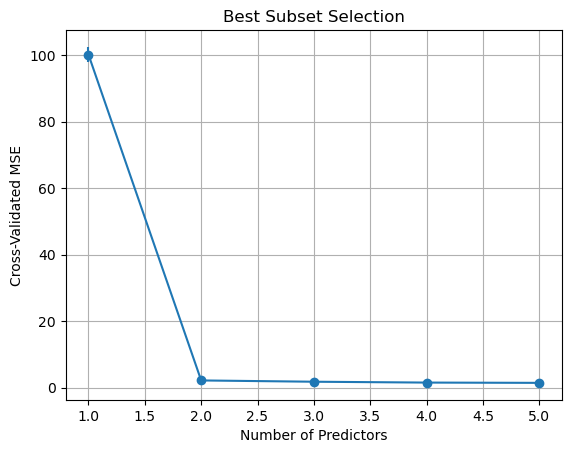

In [6]:
plt.errorbar(
    best_per_size["n_terms"],
    best_per_size["mse"],
    yerr=best_per_size["se"],
    marker="o"
)

plt.xlabel("Number of Predictors")
plt.ylabel("Cross-Validated MSE")
plt.title("Best Subset Selection")
plt.grid(True)